# Telugu Audio Hate Speech Detection - Phase 2


## This notebook includes the model trainings for audio modality:

1. **Wav2Vec2 XLS-R 300M frozen features** + LSTM and 1D-CNN classifiers (binary and 5-class).
2. **Wav2Vec2 sequence-classification model** (`superb/wav2vec2-base-superb-er`) fine-tuned for binary and 5-class tasks.
3. **Audio Spectrogram Transformer (AST)** (`MIT/ast-finetuned-audioset-10-10-0.4593`) fine-tuned for binary and 5-class tasks.


In [ ]:
!pip install -q transformers datasets torchaudio librosa soundfile

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os, glob, json, random, warnings, time
from pathlib import Path

TRAIN_CSV = "/content/train_data.csv"
TEST_CSV  = "/content/test_data.csv"

# Folder containing the audio files (including subfolders)
AUDIO_ROOTS = [
    "/content/drive/MyDrive/augmented_audios",
    "/content/drive/MyDrive/telugu_dataset",
    "/content/drive/MyDrive",
]

# All generated features, checkpoints, and reports are saved here.
OUTPUT_DIR = "/content/drive/MyDrive/telugu_hate_speech_phase2_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42
SAMPLE_RATE = 16000
MAX_AUDIO_SECONDS = 10       # same 10-second cap used in the Phase 2 sequence-classification code
BATCH_SIZE_XLSR = 8
EPOCHS_XLSR_HEAD = 20
BATCH_SIZE_HF = 2             # conservative for Colab GPUs; increase only if GPU memory allows
EPOCHS_HF = 3                 # start small; increase for final experiments

random.seed(SEED)
np_seed_placeholder = SEED
print("Output directory:", OUTPUT_DIR)

Output directory: /content/drive/MyDrive/telugu_hate_speech_phase2_outputs


In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import torchaudio
import librosa
import soundfile as sf
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

Device: cuda
GPU: Tesla T4


## Load CSV files and resolve audio paths for Colab

In [ ]:
assert os.path.isfile(TRAIN_CSV), f"Train CSV not found: {TRAIN_CSV}. Update TRAIN_CSV."
assert os.path.isfile(TEST_CSV), f"Test CSV not found: {TEST_CSV}. Update TEST_CSV."

train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)

required_columns = {"New File Path", "Binary Label", "Multi-class Label"}
for split_name, frame in [("train", train_df), ("test", test_df)]:
    missing = required_columns - set(frame.columns)
    if missing:
        raise ValueError(f"{split_name} CSV is missing columns {missing}. Found: {frame.columns.tolist()}")


audio_index = {}
for root in AUDIO_ROOTS:
    if os.path.isdir(root):
        for p in glob.iglob(os.path.join(root, "**", "*"), recursive=True):
            if os.path.isfile(p) and Path(p).suffix.lower() in {".wav", ".mp3", ".flac", ".ogg", ".m4a"}:
                audio_index.setdefault(os.path.basename(p), p)

def resolve_audio_path(path):
    path = str(path)
    if os.path.isfile(path):
        return path

    candidate = audio_index.get(os.path.basename(path))
    if candidate and os.path.isfile(candidate):
        return candidate
    return None

for frame in (train_df, test_df):
    frame["Resolved Audio Path"] = frame["New File Path"].map(resolve_audio_path)

missing_train = train_df["Resolved Audio Path"].isna().sum()
missing_test = test_df["Resolved Audio Path"].isna().sum()
print("Train rows:", len(train_df), "| unresolved audio:", missing_train)
print("Test rows:", len(test_df), "| unresolved audio:", missing_test)
print("Binary labels (train):", sorted(train_df["Binary Label"].dropna().unique().tolist()))
print("Multiclass labels (train):", sorted(train_df["Multi-class Label"].dropna().unique().tolist()))

if missing_train or missing_test:
    print("\nExamples of unresolved paths:")
    display(pd.concat([
        train_df.loc[train_df["Resolved Audio Path"].isna(), ["New File Path"]].head(5),
        test_df.loc[test_df["Resolved Audio Path"].isna(), ["New File Path"]].head(5)
    ]))
    raise FileNotFoundError(
        "Some audio files were not found. Add the correct Drive folder to AUDIO_ROOTS, "
        "or correct TRAIN_CSV / TEST_CSV, then rerun this cell."
    )

for frame in (train_df, test_df):
    frame["Binary Label"] = pd.to_numeric(frame["Binary Label"], errors="raise").astype(int)
    frame["Multi-class Label"] = pd.to_numeric(frame["Multi-class Label"], errors="raise").astype(int)

binary_classes = sorted(train_df["Binary Label"].unique().tolist())
multi_classes = sorted(train_df["Multi-class Label"].unique().tolist())
multi_names = ["C", "G", "P", "R", "NH"] if multi_classes == [0, 1, 2, 3, 4] else [str(x) for x in multi_classes]
print("Binary classes:", binary_classes, "(expected 0=Non-Hate, 1=Hate)")
print("Multiclass class IDs:", multi_classes, "| display names:", multi_names)
display(train_df.head())

Train rows: 830 | unresolved audio: 0
Test rows: 121 | unresolved audio: 0
Binary labels (train): [0, 1]
Multiclass labels (train): [0, 1, 2, 3, 4]
Binary classes: [0, 1] (expected 0=Non-Hate, 1=Hate)
Multiclass class IDs: [0, 1, 2, 3, 4] | display names: ['C', 'G', 'P', 'R', 'NH']


,File Name,New File Path,Duration,Binary Label,Multi-class Label,Resolved Audio Path
0,H_TE_002_G_F_024_001.mp3_time_shift.mp3,/content/augmented_audios/H_TE_002_G_F_024_001...,11.032063,1,1,/content/drive/MyDrive/augmented_audios/H_TE_0...
1,H_TE_002_G_M_019_001.mp3,/content/resampled_audios/Hate/Gender/H_TE_002...,7.720975,1,1,/content/drive/MyDrive/telugu_dataset/TELUGU D...
2,H_TE_002_G_M_009_002.mp3,/content/resampled_audios/Hate/Gender/H_TE_002...,6.768957,1,1,/content/drive/MyDrive/telugu_dataset/TELUGU D...
3,H_TE_002_G_F_035_002.mp3_add_noise.mp3,/content/augmented_audios/H_TE_002_G_F_035_002...,3.718437,1,1,/content/drive/MyDrive/augmented_audios/H_TE_0...
4,NH_TE_001_N_M_040_002.mp3,/content/resampled_audios/Non Hate/NH_TE_001_N...,14.444444,0,4,/content/drive/MyDrive/telugu_dataset/TELUGU D...


## Dataset overview

Train binary distribution:


,count
Binary Label,
Non-Hate,166
Hate,664


Train multiclass distribution:


,count
Multi-class Label,
0,166
1,166
2,166
3,166
4,166


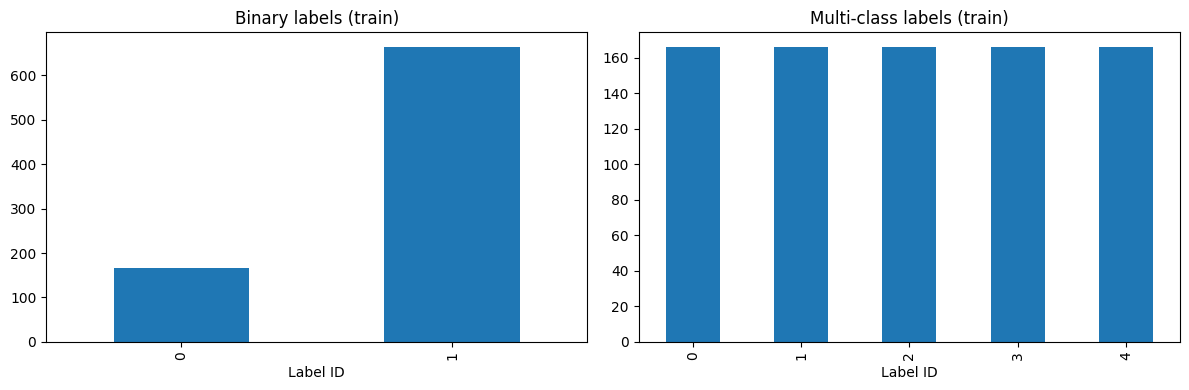

In [ ]:
print("Train binary distribution:")
display(train_df["Binary Label"].value_counts().sort_index().rename(index={0:"Non-Hate", 1:"Hate"}).to_frame("count"))
print("Train multiclass distribution:")
display(train_df["Multi-class Label"].value_counts().sort_index().to_frame("count"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train_df["Binary Label"].value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Binary labels (train)")
axes[0].set_xlabel("Label ID")
train_df["Multi-class Label"].value_counts().sort_index().plot(kind="bar", ax=axes[1])
axes[1].set_title("Multi-class labels (train)")
axes[1].set_xlabel("Label ID")
plt.tight_layout()
plt.show()

## Shared audio loader

Audio is converted to mono, resampled to 16 kHz, and capped/padded to `MAX_AUDIO_SECONDS` for the two end-to-end Hugging Face models. XLS-R feature extraction below uses the same cap so runs are reproducible.

In [ ]:
def load_audio(path, target_sr=SAMPLE_RATE, max_seconds=MAX_AUDIO_SECONDS):
    audio, sr = librosa.load(path, sr=target_sr, mono=True)
    if max_seconds is not None:
        max_len = int(target_sr * max_seconds)
        audio = audio[:max_len]
        if len(audio) < max_len:
            audio = np.pad(audio, (0, max_len - len(audio)))
    if not np.isfinite(audio).all():
        audio = np.nan_to_num(audio)
    return audio.astype(np.float32)

# Quick file check
sample_audio = load_audio(train_df.iloc[0]["Resolved Audio Path"])
print("Sample waveform shape:", sample_audio.shape, "| seconds:", len(sample_audio) / SAMPLE_RATE)

Sample waveform shape: (160000,) | seconds: 10.0


# MODEL 1 - Wav2Vec2 XLS-R 300M frozen features + LSTM / 1D-CNN

## Extract mean-pooled XLS-R embeddings (cached)

In [ ]:
from transformers import AutoConfig, Wav2Vec2FeatureExtractor, Wav2Vec2Model

XLSR_NAME = "facebook/wav2vec2-xls-r-300m"
xlsr_extractor = Wav2Vec2FeatureExtractor.from_pretrained(XLSR_NAME)
xlsr_encoder = Wav2Vec2Model.from_pretrained(XLSR_NAME).to(device)
xlsr_encoder.eval()
for param in xlsr_encoder.parameters():
    param.requires_grad = False

XLSR_CACHE = os.path.join(OUTPUT_DIR, "xlsr_mean_pooled_features_v1.npz")

def extract_xlsr_features(paths, batch_size=4):
    vectors = []
    for start in tqdm(range(0, len(paths), batch_size), desc="XLS-R embeddings"):
        batch_paths = paths[start:start + batch_size]
        audios = [load_audio(p) for p in batch_paths]
        inputs = xlsr_extractor(audios, sampling_rate=SAMPLE_RATE, return_tensors="pt",
                                padding=True, return_attention_mask=True)
        input_values = inputs["input_values"].to(device)
        attention_mask = inputs.get("attention_mask")
        if attention_mask is not None:
            attention_mask = attention_mask.to(device)
        with torch.no_grad():
            outputs = xlsr_encoder(input_values=input_values, attention_mask=attention_mask)
            hidden = outputs.last_hidden_state
            # Mean pooling over the time dimension, matching Phase 2's feature extraction approach.
            pooled = hidden.mean(dim=1)
        vectors.append(pooled.cpu().numpy().astype(np.float32))
    return np.concatenate(vectors, axis=0)

if os.path.exists(XLSR_CACHE):
    cache = np.load(XLSR_CACHE)
    X_train_xlsr, X_test_xlsr = cache["X_train"], cache["X_test"]
    print("Loaded cached features:", X_train_xlsr.shape, X_test_xlsr.shape)
else:
    X_train_xlsr = extract_xlsr_features(train_df["Resolved Audio Path"].tolist())
    X_test_xlsr = extract_xlsr_features(test_df["Resolved Audio Path"].tolist())
    np.savez_compressed(XLSR_CACHE, X_train=X_train_xlsr, X_test=X_test_xlsr)
    print("Saved features to:", XLSR_CACHE)

y_train_bin = train_df["Binary Label"].to_numpy(dtype=np.int64)
y_test_bin = test_df["Binary Label"].to_numpy(dtype=np.int64)
y_train_multi = train_df["Multi-class Label"].to_numpy(dtype=np.int64)
y_test_multi = test_df["Multi-class Label"].to_numpy(dtype=np.int64)

print("XLS-R feature shapes:", X_train_xlsr.shape, X_test_xlsr.shape)

preprocessor_config.json:   0%|          | 0.00/212 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.57k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.27GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.27GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_q.weight             | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


XLS-R embeddings:   0%|          | 0/208 [00:00<?, ?it/s]

XLS-R embeddings:   0%|          | 0/31 [00:00<?, ?it/s]

Saved features to: /content/drive/MyDrive/telugu_hate_speech_phase2_outputs/xlsr_mean_pooled_features_v1.npz
XLS-R feature shapes: (830, 1024) (121, 1024)


## Reusable training and evaluation for XLS-R LSTM / CNN

In [ ]:
def evaluate_predictions(y_true, y_pred, class_names, title):
    labels = list(range(len(class_names)))
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print("Macro F1:", round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4))
    print(classification_report(y_true, y_pred, labels=labels, target_names=class_names, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(title)
    plt.tight_layout()
    plt.show()
    return {"accuracy": accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0)}

class AudioLSTM(nn.Module):
    def __init__(self, input_size=1024, hidden_size=128, num_layers=2, num_classes=2, dropout=0.2):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers=num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0, bidirectional=True)
        self.fc = nn.Linear(hidden_size * 2, num_classes)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

class AudioCNN(nn.Module):
    def __init__(self, num_classes, dropout=0.5):
        super().__init__()
        self.conv1 = nn.Conv1d(1024, 64, kernel_size=3, padding=1)
        self.conv2 = nn.Conv1d(64, 128, kernel_size=3, padding=1)
        self.conv3 = nn.Conv1d(128, 256, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(256, 128)
        self.fc2 = nn.Linear(128, num_classes)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):  # [batch, time, 1024]
        x = x.transpose(1, 2)  # [batch, 1024, time]
        x = torch.relu(self.conv1(x))
        x = torch.relu(self.conv2(x))
        x = torch.relu(self.conv3(x))
        x = x.mean(dim=2)
        x = self.dropout(torch.relu(self.fc1(x)))
        return self.fc2(x)

def fit_torch_classifier(model, X_train, y_train, X_test, y_test, class_names,
                         run_name, epochs=EPOCHS_XLSR_HEAD, batch_size=BATCH_SIZE_XLSR, lr=1e-3):
    model = model.to(device)
    train_ds = TensorDataset(torch.tensor(X_train, dtype=torch.float32),
                             torch.tensor(y_train, dtype=torch.long))
    test_ds = TensorDataset(torch.tensor(X_test, dtype=torch.float32),
                            torch.tensor(y_test, dtype=torch.long))
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    history = []
    for epoch in range(epochs):
        model.train()
        losses = []
        for xb, yb in tqdm(train_loader, desc=f"{run_name} epoch {epoch+1}/{epochs}", leave=False):
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
        avg_loss = float(np.mean(losses))
        history.append(avg_loss)
        print(f"{run_name} | epoch {epoch+1}/{epochs} | loss={avg_loss:.4f}")
    model.eval()
    preds, truths = [], []
    with torch.no_grad():
        for xb, yb in test_loader:
            logits = model(xb.to(device))
            preds.extend(logits.argmax(dim=1).cpu().numpy())
            truths.extend(yb.numpy())
    metrics = evaluate_predictions(truths, preds, class_names, f"{run_name} confusion matrix")
    torch.save(model.state_dict(), os.path.join(OUTPUT_DIR, f"{run_name}.pth"))
    with open(os.path.join(OUTPUT_DIR, f"{run_name}_metrics.json"), "w") as f:
        json.dump({k: float(v) for k, v in metrics.items()}, f, indent=2)
    plt.figure(figsize=(6,3))
    plt.plot(range(1, len(history)+1), history, marker="o")
    plt.xlabel("Epoch"); plt.ylabel("Training loss"); plt.title(f"{run_name} loss")
    plt.tight_layout(); plt.show()
    return model, metrics

## XLS-R + LSTM - binary and multi-class

xlsr_lstm_binary epoch 1/20:   0%|          | 0/104 [00:00<?, ?it/s]

xlsr_lstm_binary | epoch 1/20 | loss=0.5069


xlsr_lstm_binary epoch 2/20:   0%|          | 0/104 [00:00<?, ?it/s]

xlsr_lstm_binary | epoch 2/20 | loss=0.4755


xlsr_lstm_binary epoch 3/20:   0%|          | 0/104 [00:00<?, ?it/s]

xlsr_lstm_binary | epoch 3/20 | loss=0.4651


... (30 outputs left out)

xlsr_lstm_binary epoch 19/20:   0%|          | 0/104 [00:00<?, ?it/s]

xlsr_lstm_binary | epoch 19/20 | loss=0.3379


xlsr_lstm_binary epoch 20/20:   0%|          | 0/104 [00:00<?, ?it/s]

xlsr_lstm_binary | epoch 20/20 | loss=0.3359
Accuracy: 0.6777
Macro F1: 0.4851
              precision    recall  f1-score   support

    Non-Hate       0.80      0.10      0.17        42
        Hate       0.67      0.99      0.80        79

    accuracy                           0.68       121
   macro avg       0.74      0.54      0.49       121
weighted avg       0.72      0.68      0.58       121



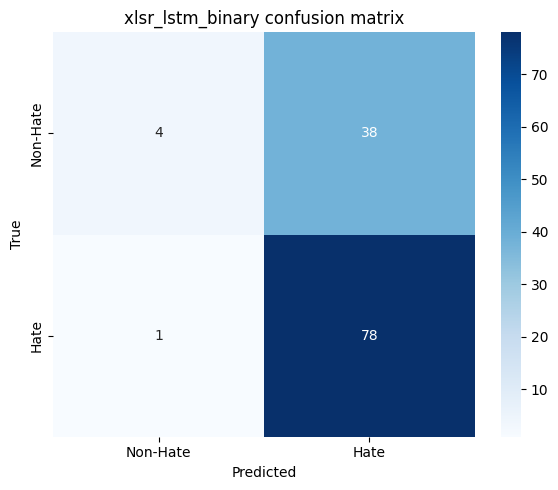

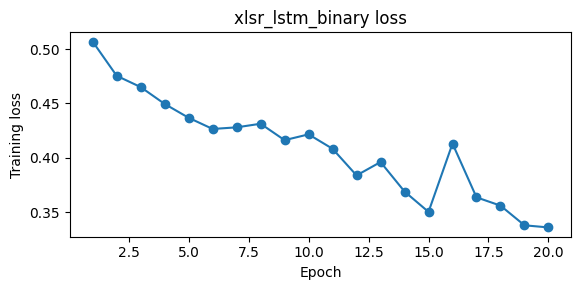

xlsr_lstm_multiclass epoch 1/20:   0%|          | 0/104 [00:00<?, ?it/s]

xlsr_lstm_multiclass | epoch 1/20 | loss=1.5792


xlsr_lstm_multiclass epoch 2/20:   0%|          | 0/104 [00:00<?, ?it/s]

xlsr_lstm_multiclass | epoch 2/20 | loss=1.4808


xlsr_lstm_multiclass epoch 3/20:   0%|          | 0/104 [00:00<?, ?it/s]

xlsr_lstm_multiclass | epoch 3/20 | loss=1.4042


... (30 outputs left out)

xlsr_lstm_multiclass epoch 19/20:   0%|          | 0/104 [00:00<?, ?it/s]

xlsr_lstm_multiclass | epoch 19/20 | loss=1.1610


xlsr_lstm_multiclass epoch 20/20:   0%|          | 0/104 [00:00<?, ?it/s]

xlsr_lstm_multiclass | epoch 20/20 | loss=1.1302
Accuracy: 0.438
Macro F1: 0.4079
              precision    recall  f1-score   support

           C       0.62      0.54      0.58        28
           G       0.69      0.36      0.47        25
           P       0.23      0.75      0.35        12
           R       0.14      0.14      0.14        14
          NH       0.60      0.43      0.50        42

    accuracy                           0.44       121
   macro avg       0.46      0.44      0.41       121
weighted avg       0.53      0.44      0.46       121



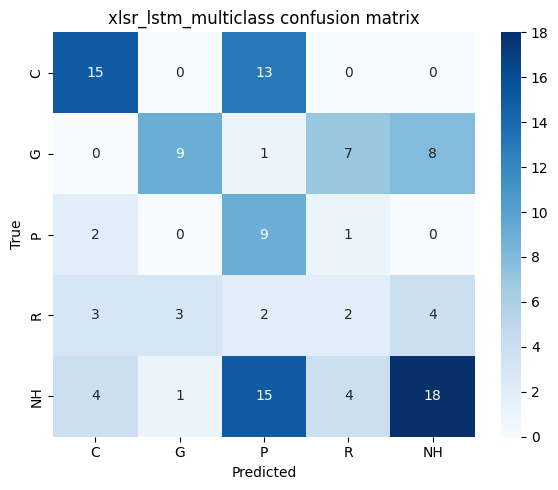

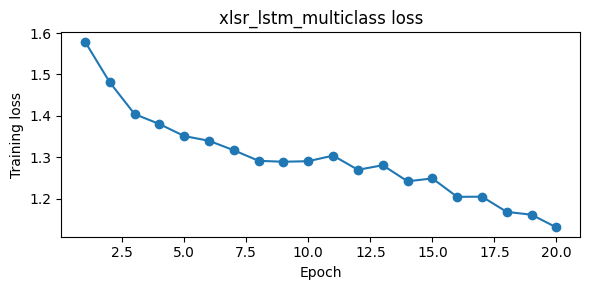

In [ ]:
X_train_seq = X_train_xlsr[:, None, :]
X_test_seq = X_test_xlsr[:, None, :]

xlsr_lstm_binary, metrics_xlsr_lstm_binary = fit_torch_classifier(
    AudioLSTM(num_classes=2), X_train_seq, y_train_bin, X_test_seq, y_test_bin,
    ["Non-Hate", "Hate"], "xlsr_lstm_binary", epochs=EPOCHS_XLSR_HEAD, lr=0.002
)

xlsr_lstm_multi, metrics_xlsr_lstm_multi = fit_torch_classifier(
    AudioLSTM(num_classes=len(multi_classes)), X_train_seq, y_train_multi, X_test_seq, y_test_multi,
    multi_names, "xlsr_lstm_multiclass", epochs=EPOCHS_XLSR_HEAD, lr=0.001
)

## XLS-R + 1D-CNN - binary and multi-class

xlsr_cnn_binary epoch 1/20:   0%|          | 0/104 [00:00<?, ?it/s]

xlsr_cnn_binary | epoch 1/20 | loss=0.5276


xlsr_cnn_binary epoch 2/20:   0%|          | 0/104 [00:00<?, ?it/s]

xlsr_cnn_binary | epoch 2/20 | loss=0.4652


xlsr_cnn_binary epoch 3/20:   0%|          | 0/104 [00:00<?, ?it/s]

xlsr_cnn_binary | epoch 3/20 | loss=0.4702


... (30 outputs left out)

xlsr_cnn_binary epoch 19/20:   0%|          | 0/104 [00:00<?, ?it/s]

xlsr_cnn_binary | epoch 19/20 | loss=0.3758


xlsr_cnn_binary epoch 20/20:   0%|          | 0/104 [00:00<?, ?it/s]

xlsr_cnn_binary | epoch 20/20 | loss=0.3809
Accuracy: 0.6529
Macro F1: 0.395
              precision    recall  f1-score   support

    Non-Hate       0.00      0.00      0.00        42
        Hate       0.65      1.00      0.79        79

    accuracy                           0.65       121
   macro avg       0.33      0.50      0.40       121
weighted avg       0.43      0.65      0.52       121



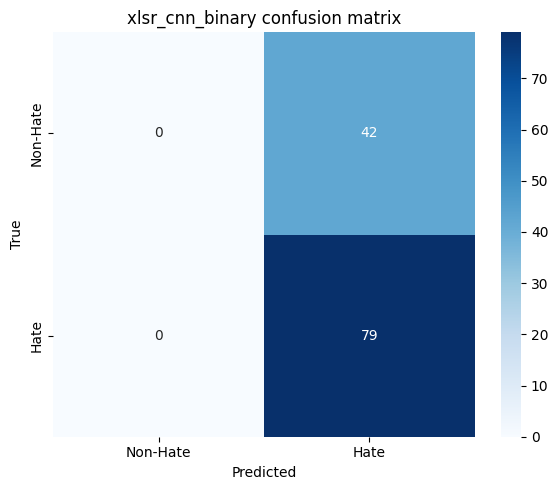

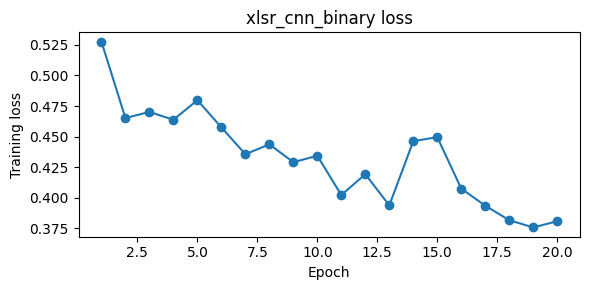

xlsr_cnn_multiclass epoch 1/20:   0%|          | 0/104 [00:00<?, ?it/s]

xlsr_cnn_multiclass | epoch 1/20 | loss=1.6124


xlsr_cnn_multiclass epoch 2/20:   0%|          | 0/104 [00:00<?, ?it/s]

xlsr_cnn_multiclass | epoch 2/20 | loss=1.5963


xlsr_cnn_multiclass epoch 3/20:   0%|          | 0/104 [00:00<?, ?it/s]

xlsr_cnn_multiclass | epoch 3/20 | loss=1.5187


... (30 outputs left out)

xlsr_cnn_multiclass epoch 19/20:   0%|          | 0/104 [00:00<?, ?it/s]

xlsr_cnn_multiclass | epoch 19/20 | loss=1.4250


xlsr_cnn_multiclass epoch 20/20:   0%|          | 0/104 [00:00<?, ?it/s]

xlsr_cnn_multiclass | epoch 20/20 | loss=1.4200
Accuracy: 0.4215
Macro F1: 0.3122
              precision    recall  f1-score   support

           C       0.49      0.64      0.55        28
           G       0.67      0.08      0.14        25
           P       0.19      0.67      0.30        12
           R       0.00      0.00      0.00        14
          NH       0.59      0.55      0.57        42

    accuracy                           0.42       121
   macro avg       0.39      0.39      0.31       121
weighted avg       0.47      0.42      0.38       121



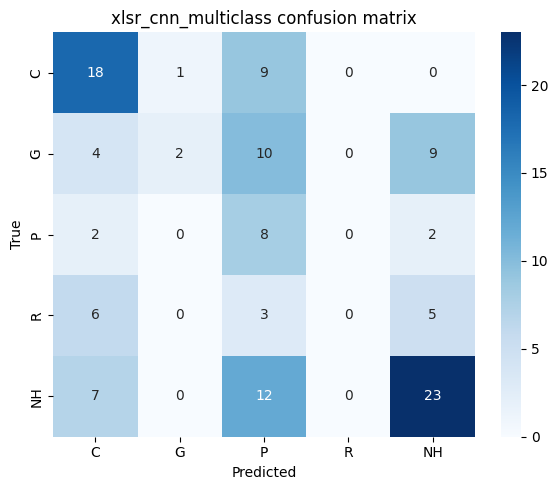

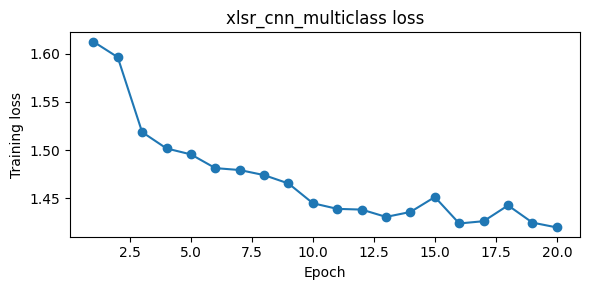

In [ ]:
xlsr_cnn_binary, metrics_xlsr_cnn_binary = fit_torch_classifier(
    AudioCNN(num_classes=2), X_train_seq, y_train_bin, X_test_seq, y_test_bin,
    ["Non-Hate", "Hate"], "xlsr_cnn_binary", epochs=EPOCHS_XLSR_HEAD, lr=0.001
)

xlsr_cnn_multi, metrics_xlsr_cnn_multi = fit_torch_classifier(
    AudioCNN(num_classes=len(multi_classes)), X_train_seq, y_train_multi, X_test_seq, y_test_multi,
    multi_names, "xlsr_cnn_multiclass", epochs=EPOCHS_XLSR_HEAD, lr=0.001
)

# MODEL 2 - Wav2Vec2 sequence-classification (`superb/wav2vec2-base-superb-er`)

In [ ]:
from transformers import Wav2Vec2FeatureExtractor, Wav2Vec2ForSequenceClassification, TrainingArguments, Trainer
from sklearn.metrics import precision_recall_fscore_support

INDIC_NAME = "superb/wav2vec2-base-superb-er"
indic_extractor = Wav2Vec2FeatureExtractor.from_pretrained(INDIC_NAME)

class AudioClassificationDataset(Dataset):
    def __init__(self, frame, label_col, feature_extractor, max_seconds=MAX_AUDIO_SECONDS):
        self.frame = frame.reset_index(drop=True)
        self.label_col = label_col
        self.feature_extractor = feature_extractor
        self.max_seconds = max_seconds
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        audio = load_audio(row["Resolved Audio Path"], max_seconds=self.max_seconds)
        item = self.feature_extractor(audio, sampling_rate=SAMPLE_RATE, return_tensors="pt",
                                      padding="max_length", max_length=int(SAMPLE_RATE*self.max_seconds),
                                      truncation=True)
        return {
            "input_values": item["input_values"].squeeze(0),
            "labels": int(row[self.label_col])
        }

def make_hf_metrics(class_names):
    def compute_metrics(eval_pred):
        logits, labels = eval_pred
        preds = np.argmax(logits, axis=1)
        return {
            "accuracy": accuracy_score(labels, preds),
            "macro_f1": f1_score(labels, preds, average="macro", zero_division=0)
        }
    return compute_metrics


def run_wav2vec2_finetune(label_col, class_names, run_name):
    num_labels = len(class_names)

    # Load model configuration
    config = AutoConfig.from_pretrained(INDIC_NAME)

    # Configure labels for our hate-speech classification task
    config.num_labels = num_labels
    config.id2label = {
        i: name for i, name in enumerate(class_names)
    }
    config.label2id = {
        name: i for i, name in enumerate(class_names)
    }

    config.use_weighted_layer_sum = False

    # Load pretrained model with a new classification head
    model = Wav2Vec2ForSequenceClassification.from_pretrained(
        INDIC_NAME,
        config=config,
        ignore_mismatched_sizes=True
    )

    train_ds = AudioClassificationDataset(train_df, label_col, indic_extractor)
    test_ds = AudioClassificationDataset(test_df, label_col, indic_extractor)

    args = TrainingArguments(
        output_dir=os.path.join(
            OUTPUT_DIR, run_name + "_trainer"
        ),
        eval_strategy="epoch",
        save_strategy="epoch",
        learning_rate=1e-5,
        per_device_train_batch_size=BATCH_SIZE_HF,
        per_device_eval_batch_size=BATCH_SIZE_HF,
        num_train_epochs=EPOCHS_HF,
        weight_decay=0.01,
        fp16=torch.cuda.is_available(),
        logging_steps=10,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        save_total_limit=1,
        report_to="none",
        seed=SEED,
        dataloader_num_workers=0
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=test_ds,
        compute_metrics=make_hf_metrics(class_names)
    )

    trainer.train()
    print("Evaluation:", trainer.evaluate())
    prediction_output = trainer.predict(test_ds)
    preds = np.argmax(prediction_output.predictions, axis=1)

    metrics = evaluate_predictions(
        prediction_output.label_ids,
        preds,
        class_names,
        f"{run_name} confusion matrix"
    )

    # Save model and feature extractor
    save_path = os.path.join(OUTPUT_DIR, run_name)
    os.makedirs(save_path, exist_ok=True)

    trainer.save_model(save_path)
    indic_extractor.save_pretrained(save_path)

    with open(
        os.path.join(OUTPUT_DIR, f"{run_name}_metrics.json"), "w"
    ) as f:
        json.dump(
            {k: float(v) for k, v in metrics.items()},
            f,
            indent=2
        )

    return trainer, metrics

## Wav2Vec2 - binary classification

Loading weights:   0%|          | 0/215 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForSequenceClassification LOAD REPORT from: superb/wav2vec2-base-superb-er
Key               | Status     |                                                                                       
------------------+------------+---------------------------------------------------------------------------------------
layer_weights     | UNEXPECTED |                                                                                       
classifier.bias   | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([4]) vs model:torch.Size([2])          
classifier.weight | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([4, 256]) vs model:torch.Size([2, 256])

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.648449,1.471599,0.735537,0.666667
2,0.257029,1.541769,0.735537,0.725624
3,0.006720,1.363972,0.776860,0.762244


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.006720,1.363972,3,0.776860,0.762244


Evaluation: {'eval_loss': 1.3639721870422363, 'eval_accuracy': 0.7768595041322314, 'eval_macro_f1': 0.7622443781384178}


Accuracy: 0.7769
Macro F1: 0.7622
              precision    recall  f1-score   support

    Non-Hate       0.65      0.76      0.70        42
        Hate       0.86      0.78      0.82        79

    accuracy                           0.78       121
   macro avg       0.76      0.77      0.76       121
weighted avg       0.79      0.78      0.78       121



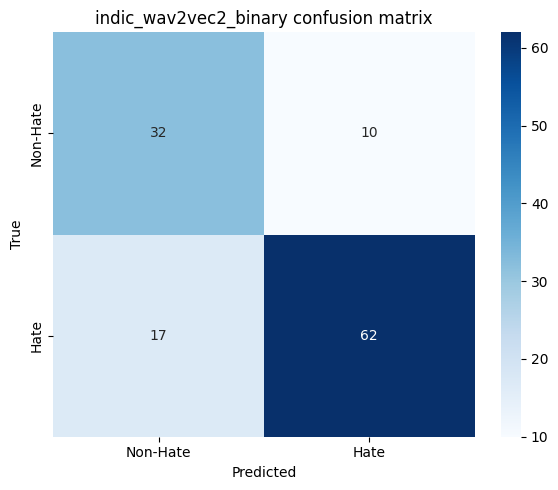

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
indic_binary_trainer, indic_binary_metrics = run_wav2vec2_finetune(
    "Binary Label", ["Non-Hate", "Hate"], "indic_wav2vec2_binary"
)

## Wav2Vec2 - multi-class classification

Loading weights:   0%|          | 0/215 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForSequenceClassification LOAD REPORT from: superb/wav2vec2-base-superb-er
Key               | Status     |                                                                                       
------------------+------------+---------------------------------------------------------------------------------------
layer_weights     | UNEXPECTED |                                                                                       
classifier.bias   | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([4]) vs model:torch.Size([5])          
classifier.weight | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([4, 256]) vs model:torch.Size([5, 256])

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.657819,1.465448,0.429752,0.345632
2,1.268576,1.624585,0.471074,0.378225
3,0.923324,1.690176,0.454545,0.393545


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.923324,1.690176,3,0.454545,0.393545


Evaluation: {'eval_loss': 1.690176010131836, 'eval_accuracy': 0.45454545454545453, 'eval_macro_f1': 0.39354488872242416}


Accuracy: 0.4545
Macro F1: 0.3935
              precision    recall  f1-score   support

           C       0.33      0.18      0.23        28
           G       0.29      0.24      0.26        25
           P       0.58      0.58      0.58        12
           R       0.25      0.21      0.23        14
          NH       0.56      0.81      0.66        42

    accuracy                           0.45       121
   macro avg       0.40      0.41      0.39       121
weighted avg       0.42      0.45      0.42       121



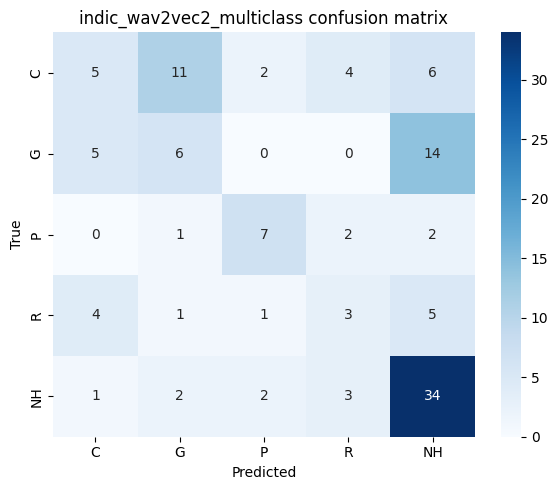

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
indic_multi_trainer, indic_multi_metrics = run_wav2vec2_finetune(
    "Multi-class Label", multi_names, "indic_wav2vec2_multiclass"
)

# MODEL 3 - Audio Spectrogram Transformer (AST)

In [ ]:
from transformers import AutoFeatureExtractor, AutoModelForAudioClassification

AST_NAME = "MIT/ast-finetuned-audioset-10-10-0.4593"
ast_extractor = AutoFeatureExtractor.from_pretrained(AST_NAME)

class ASTAudioDataset(Dataset):
    def __init__(self, frame, label_col, extractor):
        self.frame = frame.reset_index(drop=True)
        self.label_col = label_col
        self.extractor = extractor
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        audio = load_audio(row["Resolved Audio Path"], max_seconds=MAX_AUDIO_SECONDS)
        enc = self.extractor(audio, sampling_rate=SAMPLE_RATE, return_tensors="pt",
                             padding="max_length", max_length=int(SAMPLE_RATE*MAX_AUDIO_SECONDS),
                             truncation=True)
        # AST feature extractors generally expose input_values; preserve all model inputs except batch dimension.
        result = {k: v.squeeze(0) for k, v in enc.items()}
        result["labels"] = torch.tensor(int(row[self.label_col]), dtype=torch.long)
        return result

def run_ast_finetune(label_col, class_names, run_name):
    model = AutoModelForAudioClassification.from_pretrained(
        AST_NAME, num_labels=len(class_names), ignore_mismatched_sizes=True,
        label2id={name:i for i,name in enumerate(class_names)},
        id2label={i:name for i,name in enumerate(class_names)}
    )
    train_ds = ASTAudioDataset(train_df, label_col, ast_extractor)
    test_ds = ASTAudioDataset(test_df, label_col, ast_extractor)
    args = TrainingArguments(
        output_dir=os.path.join(OUTPUT_DIR, run_name + "_trainer"),
        eval_strategy="epoch",
        save_strategy="epoch",
        learning_rate=2e-5,
        per_device_train_batch_size=BATCH_SIZE_HF,
        per_device_eval_batch_size=BATCH_SIZE_HF,
        num_train_epochs=EPOCHS_HF,
        weight_decay=0.01,
        fp16=torch.cuda.is_available(),
        logging_steps=10,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        save_total_limit=1,
        report_to="none",
        seed=SEED,
        dataloader_num_workers=0
    )
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=test_ds,
                      compute_metrics=make_hf_metrics(class_names))
    trainer.train()
    print("Evaluation:", trainer.evaluate())
    output = trainer.predict(test_ds)
    preds = np.argmax(output.predictions, axis=1)
    metrics = evaluate_predictions(output.label_ids, preds, class_names, f"{run_name} confusion matrix")
    trainer.save_model(os.path.join(OUTPUT_DIR, run_name))
    ast_extractor.save_pretrained(os.path.join(OUTPUT_DIR, run_name))
    with open(os.path.join(OUTPUT_DIR, f"{run_name}_metrics.json"), "w") as f:
        json.dump({k: float(v) for k, v in metrics.items()}, f, indent=2)
    return trainer, metrics

preprocessor_config.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

## AST - binary classification

config.json:   0%|          | 0.00/26.8k [00:00<?, ?B/s]

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `527`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

[transformers] ASTForAudioClassification LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                     | Status   |                                                                                         
------------------------+----------+-----------------------------------------------------------------------------------------
classifier.dense.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527]) vs model:torch.Size([2])          
classifier.dense.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527, 768]) vs model:torch.Size([2, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


... (4 outputs left out)

[transformers] There were missing keys in the checkpoint model loaded: ['audio_spectrogram_transformer.layers.0.attention.q_proj.weight', 'audio_spectrogram_transformer.layers.0.attention.q_proj.bias', 'audio_spectrogram_transformer.layers.0.attention.k_proj.weight', 'audio_spectrogram_transformer.layers.0.attention.k_proj.bias', 'audio_spectrogram_transformer.layers.0.attention.v_proj.weight', 'audio_spectrogram_transformer.layers.0.attention.v_proj.bias', 'audio_spectrogram_transformer.layers.0.attention.o_proj.weight', 'audio_spectrogram_transformer.layers.0.attention.o_proj.bias', 'audio_spectrogram_transformer.layers.0.layernorm_before.weight', 'audio_spectrogram_transformer.layers.0.layernorm_before.bias', 'audio_spectrogram_transformer.layers.0.layernorm_after.weight', 'audio_spectrogram_transformer.layers.0.layernorm_after.bias', 'audio_spectrogram_transformer.layers.0.mlp.fc1.weight', 'audio_spectrogram_transformer.layers.0.mlp.fc1.bias', 'audio_spectrogram_transformer.layers.

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.000958,0.839517,3,0.859504,0.844131


Evaluation: {'eval_loss': 0.8395169973373413, 'eval_accuracy': 0.859504132231405, 'eval_macro_f1': 0.8441312419489277}


Accuracy: 0.8595
Macro F1: 0.8441
              precision    recall  f1-score   support

    Non-Hate       0.80      0.79      0.80        42
        Hate       0.89      0.90      0.89        79

    accuracy                           0.86       121
   macro avg       0.85      0.84      0.84       121
weighted avg       0.86      0.86      0.86       121



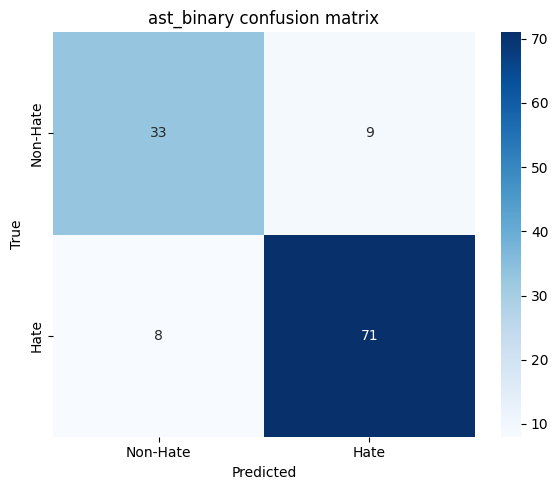

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
ast_binary_trainer, ast_binary_metrics = run_ast_finetune(
    "Binary Label", ["Non-Hate", "Hate"], "ast_binary"
)

## AST - multi-class classification

[transformers] You passed `num_labels=5` which is incompatible to the `id2label` map of length `527`.


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

[transformers] ASTForAudioClassification LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                     | Status   |                                                                                         
------------------------+----------+-----------------------------------------------------------------------------------------
classifier.dense.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527]) vs model:torch.Size([5])          
classifier.dense.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527, 768]) vs model:torch.Size([5, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.027533,1.247210,0.652893,0.587304
2,0.678759,1.376796,0.661157,0.596520
3,0.008856,1.476457,0.702479,0.622943


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['audio_spectrogram_transformer.layers.0.attention.q_proj.weight', 'audio_spectrogram_transformer.layers.0.attention.q_proj.bias', 'audio_spectrogram_transformer.layers.0.attention.k_proj.weight', 'audio_spectrogram_transformer.layers.0.attention.k_proj.bias', 'audio_spectrogram_transformer.layers.0.attention.v_proj.weight', 'audio_spectrogram_transformer.layers.0.attention.v_proj.bias', 'audio_spectrogram_transformer.layers.0.attention.o_proj.weight', 'audio_spectrogram_transformer.layers.0.attention.o_proj.bias', 'audio_spectrogram_transformer.layers.0.layernorm_before.weight', 'audio_spectrogram_transformer.layers.0.layernorm_before.bias', 'audio_spectrogram_transformer.layers.0.layernorm_after.weight', 'audio_spectrogram_transformer.layers.0.layernorm_after.bias', 'audio_spectrogram_transformer.layers.0.mlp.fc1.weight', 'audio_spectrogram_transformer.layers.0.mlp.fc1.bias', 'audio_spectrogram_transformer.layers.

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.008856,1.476457,3,0.702479,0.622943


Evaluation: {'eval_loss': 1.4764574766159058, 'eval_accuracy': 0.7024793388429752, 'eval_macro_f1': 0.6229432001171131}


Accuracy: 0.7025
Macro F1: 0.6229
              precision    recall  f1-score   support

           C       0.85      0.79      0.81        28
           G       0.71      0.60      0.65        25
           P       0.58      0.58      0.58        12
           R       0.38      0.21      0.27        14
          NH       0.70      0.90      0.79        42

    accuracy                           0.70       121
   macro avg       0.64      0.62      0.62       121
weighted avg       0.69      0.70      0.69       121



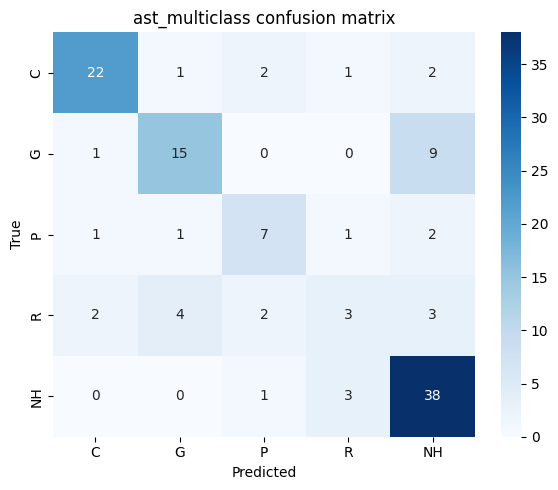

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
ast_multi_trainer, ast_multi_metrics = run_ast_finetune(
    "Multi-class Label", multi_names, "ast_multiclass"
)

## Compare all completed experiments

In [ ]:
results = {}
for name in [
    "metrics_xlsr_lstm_binary", "metrics_xlsr_lstm_multi",
    "metrics_xlsr_cnn_binary", "metrics_xlsr_cnn_multi",
]:

    pass

experiment_metrics = {
    "XLS-R + LSTM (binary)": metrics_xlsr_lstm_binary,
    "XLS-R + LSTM (multi-class)": metrics_xlsr_lstm_multi,
    "XLS-R + 1D-CNN (binary)": metrics_xlsr_cnn_binary,
    "XLS-R + 1D-CNN (multi-class)": metrics_xlsr_cnn_multi,
    "Wav2Vec2 (binary)": indic_binary_metrics,
    "Wav2Vec2 (multi-class)": indic_multi_metrics,
    "AST (binary)": ast_binary_metrics,
    "AST (multi-class)": ast_multi_metrics,
}
comparison = pd.DataFrame([
    {"Model": name, "Accuracy": float(m["accuracy"]), "Macro F1": float(m["macro_f1"])}
    for name, m in experiment_metrics.items()
])
display(comparison.sort_values("Macro F1", ascending=False).reset_index(drop=True))
comparison.to_csv(os.path.join(OUTPUT_DIR, "model_comparison.csv"), index=False)
print("Saved comparison to:", os.path.join(OUTPUT_DIR, "model_comparison.csv"))

,Model,Accuracy,Macro F1
0,AST (binary),0.859504,0.844131
1,Wav2Vec2 (binary),0.776860,0.762244
2,AST (multi-class),0.702479,0.622943
3,XLS-R + LSTM (binary),0.677686,0.485106
4,XLS-R + LSTM (multi-class),0.438017,0.407924
5,XLS-R + 1D-CNN (binary),0.652893,0.395000
6,Wav2Vec2 (multi-class),0.454545,0.393545
7,XLS-R + 1D-CNN (multi-class),0.421488,0.312180


Saved comparison to: /content/drive/MyDrive/telugu_hate_speech_phase2_outputs/model_comparison.csv
